In [ ]:
# Instalar dependencias
# amazon-braket-sdk proporciona acceso a simuladores locales y hardware analógico como QuEra Aquila en AWS Braket
!pip install -q "amazon-braket-sdk>=1.127.0" matplotlib numpy

# Computación cuántica analógica con átomos neutros: QuEra Aquila

En los **Notebooks 01 y 02** trabajamos con el modelo de **puertas lógicas discretas** (IBM Quantum, IQM Resonance e IonQ). En ese paradigma, definimos cúbits individuales y aplicamos compuertas unitarias secuenciales ($H$, $CX$, etc.).

Sin embargo, ciertas tecnologías cuánticas operan bajo un paradigma completamente diferente: la **simulación analógica de hamiltonianos (AHS - Analog Hamiltonian Simulation)**.

| Proveedor / Dispositivo | Tecnología | Paradigma | Unidades de cómputo |
|---|---|---|---|
| **IBM Fez / Kingston** | Superconductores | Puertas lógicas | Cúbits acoplados en red pesada de hexágonos |
| **IQM Emerald / Garnet** | Superconductores | Puertas lógicas | Cúbits en resonador estrella / rejilla |
| **IonQ Aria / Forte** | Iones atrapados | Puertas lógicas | Cúbits all-to-all |
| **QuEra Aquila** | Átomos neutros ($^{87}\text{Rb}$) | **Analógico (AHS)** | Hasta 256 átomos en pinzas ópticas (*optical tweezers*) |

### ¿Cómo funciona QuEra Aquila?
Aquila **no implementa compuertas lógicas digitales**. En su lugar:
1. Atrapa hasta **256 átomos neutros de Rubidio ($^{87}\text{Rb}$)** en una cámara de ultra-alto vacío mediante trampas de luz láser (*optical tweezers*), permitiendo definir con precisión micrométrica sus posiciones en 2D.
2. Un campo láser global ilumina los átomos excitándolos de su estado fundamental $|g\rangle$ a un estado de Rydberg de muy alta energía $|r\rangle$.
3. La colección de átomos evoluciona conjuntamente de forma continua según el **Hamiltoniano de muchos cuerpos**:

$$
H(t) = \sum_k \frac{\Omega(t)}{2}\left(|g\rangle\langle r|_k + |r\rangle\langle g|_k\right) - \sum_k \Delta(t)\, n_k + \sum_{j<k} \frac{C_6}{|\mathbf{r}_j - \mathbf{r}_k|^6}\, n_j n_k
$$

Donde:
* $\Omega(t)$ (**Frecuencia Rabi**): Controla la tasa de transición coherente entre el estado fundamental $|g\rangle$ y el estado excitado de Rydberg $|r\rangle$.
* $\Delta(t)$ (**Desintonía / Detuning**): Controla el desplazamiento energético de $|r\rangle$. Cuando $\Delta > 0$, poblar el estado $|r\rangle$ es energéticamente favorable.
* $n_k = |r\rangle\langle r|_k$: Operador de número (1 si el átomo $k$ está en estado Rydberg, 0 si está en el fundamental).
* $C_6 / |\mathbf{r}_j - \mathbf{r}_k|^6$: Fuerte interacción repulsiva de Van der Waals entre átomos cuando ambos están simultáneamente en el estado $|r\rangle$ ($C_6 \approx 5.42 \times 10^{-24}\text{ rad}\cdot\text{m}^6/\text{s}$ para $^{87}\text{Rb}$ en estado $70S$).


## El Bloqueo de Rydberg (*Rydberg Blockade*)

La física fundamental de los átomos neutros se basa en el **bloqueo de Rydberg**: debido a la intensa interacción $C_6 / r^6$, si dos átomos están más cerca que una distancia crítica denominada **radio de bloqueo** ($R_b$), el coste energético de excitar ambos átomos simultáneamente al estado $|r\rangle$ es tan grande que el láser no puede superar la penalización.

El radio de bloqueo $R_b$ se define en el punto donde la interacción Van der Waals iguala la energía del campo láser $\Omega$:
$$
\frac{C_6}{R_b^6} = \Omega \implies R_b = \left(\frac{C_6}{\Omega}\right)^{1/6}
$$

El comportamiento del sistema depende directamente del cociente entre el radio de bloqueo $R_b$ y la separación entre átomos $a$:
* **$R_b / a < 1$**: Los átomos vecinos no se bloquean mutuamente; la mayoría puede excitarse a $|r\rangle$.
* **$1 < R_b / a < 2$**: Cada átomo en $|r\rangle$ bloquea a sus vecinos inmediatos. Al realizar un barrido adiabático, el sistema adopta un orden antiferromagnético alterno **$|r\,g\,r\,g\dots\rangle$** o **$|g\,r\,g\,r\dots\rangle$** (conocido como **fase $Z_2$**).
* **$2 < R_b / a < 3$**: Cada átomo bloquea a dos vecinos a cada lado, dando lugar a un patrón de periodo 3 **$|r\,g\,g\,r\,g\,g\dots\rangle$** (**fase $Z_3$**).


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from braket.ahs.atom_arrangement import AtomArrangement
from braket.ahs.driving_field import DrivingField
from braket.ahs.analog_hamiltonian_simulation import AnalogHamiltonianSimulation

# Coeficiente Van der Waals C6 para Rb-87 en el estado Rydberg 70S (rad·m^6/s)
C6 = 5.42e-24

def blockade_radius_um(omega_rad_per_us: float) -> float:
    """Calcula el radio de bloqueo de Rydberg Rb en micrómetros para una frecuencia Rabi dada (en rad/µs)."""
    omega_si = omega_rad_per_us * 1e6  # rad/s
    return (C6 / omega_si) ** (1 / 6) * 1e6

def chain_register(n_atoms: int, spacing_um: float) -> AtomArrangement:
    """Coloca n átomos en una cadena unidimensional con espaciado regular (en micrómetros)."""
    register = AtomArrangement()
    for k in range(n_atoms):
        # Redondeamos al nanómetro para evitar problemas de precisión flotante (Aquila tiene resolución de 0.1 µm)
        register.add((round(k * spacing_um * 1e-6, 9), 0.0))
    return register

def drive_schedule(omega_rad_per_us: float, sweep_ratio: float, duration_us: float) -> dict[str, list[float]]:
    """
    Define el barrido adiabático del pulso láser:
    - Rampa de subida de la amplitud Rabi Ω
    - Barrido lineal de la desintonía de -Δ₀ a +Δ₀
    - Rampa de bajada de Ω
    """
    omega = omega_rad_per_us * 1e6
    delta = sweep_ratio * omega
    total, ramp = duration_us * 1e-6, 0.1e-6
    return {
        "times": [0.0, ramp, total - ramp, total],
        "amplitudes": [0.0, omega, omega, 0.0],
        "detunings": [-delta, -delta, delta, delta],
        "phases": [0.0, 0.0, 0.0, 0.0],
    }

def build_program(n_atoms: int, spacing_um: float, omega_rad_per_us: float, sweep_ratio: float, duration_us: float):
    """Construye el programa analógico completo (AnalogHamiltonianSimulation) combinando registro y pulsos."""
    register = chain_register(n_atoms, spacing_um)
    drive = DrivingField.from_lists(**drive_schedule(omega_rad_per_us, sweep_ratio, duration_us))
    return AnalogHamiltonianSimulation(register=register, hamiltonian=drive)


### Geometría y radio de bloqueo: Cadena de 7 átomos

Definimos una cadena lineal de **7 átomos**, espaciados $a = 5.7\ \mu\text{m}$, con $\Omega = 6.3\ \text{rad}/\mu\text{s}$.
Visualicemos las posiciones de los átomos en el plano 2D y el alcance del radio de bloqueo $R_b$ sobre los vecinos.


Radio de bloqueo Rb: 9.75 µm
Espaciado entre átomos a: 5.70 µm
Cociente Rb / a: 1.71
➡️ Régimen: Bloqueo de primeros vecinos. Esperamos el orden alterno Z₂ (rgrgrgr o grgrgrg).


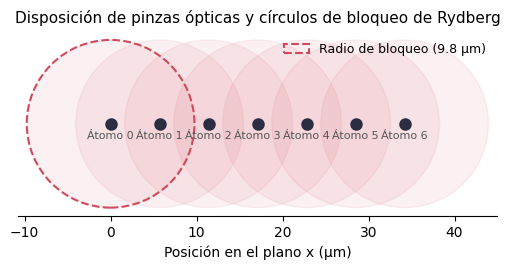

In [3]:
# Parámetros del experimento
n_atoms = 7
spacing_um = 5.7
omega_rad_per_us = 6.3
sweep_ratio = 5.0
duration_us = 4.0
shots = 100

blockade_um = blockade_radius_um(omega_rad_per_us)
ratio = blockade_um / spacing_um

print(f"Radio de bloqueo Rb: {blockade_um:.2f} µm")
print(f"Espaciado entre átomos a: {spacing_um:.2f} µm")
print(f"Cociente Rb / a: {ratio:.2f}")

if ratio < 1:
    print("➡️ Régimen: Vecinos sin bloqueo mutuo (se espera la mayoría en r).")
elif ratio < 2:
    print("➡️ Régimen: Bloqueo de primeros vecinos. Esperamos el orden alterno Z₂ (rgrgrgr o grgrgrg).")
elif ratio < 3:
    print("➡️ Régimen: Bloqueo de segundos vecinos. Esperamos orden Z₃ (rggrgg...).")
else:
    print("➡️ Régimen: Bloqueo de largo alcance. Muy pocas excitaciones posibles.")

# Visualización gráfica de los átomos y radio de bloqueo
fig, ax = plt.subplots(figsize=(8.5, 2.8))
for k in range(n_atoms):
    x = k * spacing_um
    ax.add_patch(plt.Circle((x, 0), blockade_um, color="#d1495b", alpha=0.08))
    ax.plot(x, 0, "o", color="#2b2d42", ms=8)
    ax.text(x, -1.8, f"Átomo {k}", ha="center", fontsize=8, color="#555555")

# Círculo representativo para el átomo 0
ax.add_patch(plt.Circle((0, 0), blockade_um, fill=False, ls="--", color="#d1495b", lw=1.5, label=f"Radio de bloqueo ({blockade_um:.1f} µm)"))

ax.set_xlim(-blockade_um - 1, (n_atoms - 1) * spacing_um + blockade_um + 1)
ax.set_ylim(-blockade_um - 1, blockade_um + 1)
ax.set_aspect("equal")
ax.set_xlabel("Posición en el plano x (µm)")
ax.set_yticks([])
ax.set_title("Disposición de pinzas ópticas y círculos de bloqueo de Rydberg", fontsize=11)
ax.legend(loc="upper right", frameon=False, fontsize=9)
ax.spines[["top", "right", "left"]].set_visible(False)
fig.tight_layout()
plt.show()


### El perfil de control del láser (Drive Schedule)

A diferencia de un circuito cuántico donde se aplican compuertas discretas secuenciales, en computación analógica programamos la evolución temporal continua de la amplitud y la desintonía del láser:
- **Amplitud Rabi $\Omega(t)$**: Enciende suavemente el acoplamiento óptico, lo mantiene constante durante la mayor parte del pulso, y se apaga al final para medir en la base computacional.
- **Desintonía $\Delta(t)$**: Comienza en un valor negativo grande $-\Delta_0$ (el estado fundamental es $|g\dots g\rangle$). A medida que $\Delta(t)$ barre suavemente hacia $+\Delta_0$, el estado de menor energía pasa a ser el estado ordenado antiferromagnético $Z_2$. Por el **teorema adiabático**, el sistema se mantiene en el estado fundamental a lo largo de toda la evolución.


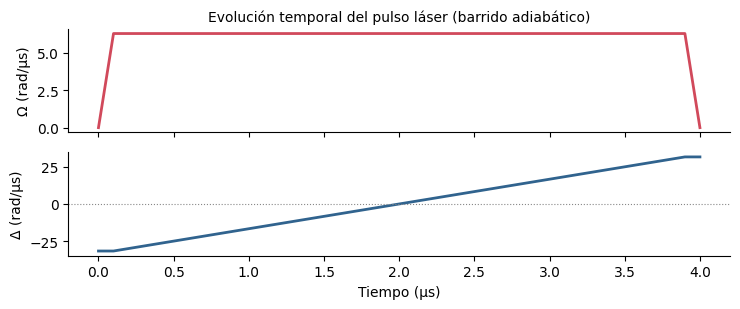

In [4]:
sched = drive_schedule(omega_rad_per_us, sweep_ratio, duration_us)
t_us = [x * 1e6 for x in sched["times"]]
omega_vals = [x / 1e6 for x in sched["amplitudes"]]
delta_vals = [x / 1e6 for x in sched["detunings"]]

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(7.5, 3.2), sharex=True)
ax_top.plot(t_us, omega_vals, color="#d1495b", lw=2)
ax_top.set_ylabel("Ω (rad/µs)")
ax_top.set_title("Evolución temporal del pulso láser (barrido adiabático)", fontsize=10)

ax_bot.plot(t_us, delta_vals, color="#30638e", lw=2)
ax_bot.axhline(0, color="#888888", lw=0.8, ls=":")
ax_bot.set_ylabel("Δ (rad/µs)")
ax_bot.set_xlabel("Tiempo (µs)")

for ax in (ax_top, ax_bot):
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()


## Simulación local con Amazon Braket (`braket_ahs`)

Amazon Braket incluye un simulador local de hamiltonianos analógicos (`LocalSimulator("braket_ahs")`) que resuelve numéricamente la ecuación de Schrödinger dependiente del tiempo integrando el estado cuántico paso a paso.

> 💡 **Nota sobre el espacio de Hilbert:** La simulación clásica en tu portátil calcula la evolución exacta en un espacio de Hilbert de $2^N$ dimensiones. Para 7 átomos ($2^7 = 128$ amplitudes) tarda menos de 1 segundo. Para 20 átomos se vuelve intratable en un portátil. Aquila ejecuta **256 átomos** de forma nativa sin ningún cuello de botella de memoria clásica.


In [5]:
from collections import Counter
from braket.devices import LocalSimulator

def shot_counts(measurements) -> tuple[dict[str, int], int]:
    """
    Procesa las mediciones de Braket:
    - pre_sequence: 1 si el átomo fue atrapado con éxito en la pinza óptica antes del pulso.
    - post_sequence: 0 si el átomo pasó a estado Rydberg (o fue eyectado de la trampa), 1 si se mantuvo en fundamental.
    Mapeamos: post_sequence 0 -> 'r' (Rydberg), 1 -> 'g' (ground/fundamental).
    Filtramos únicamente los disparos en los que todos los átomos fueron cargados con éxito.
    """
    counts = Counter()
    kept = 0
    for shot in measurements:
        pre, post = list(shot.pre_sequence), list(shot.post_sequence)
        if not all(pre):
            continue
        kept += 1
        counts["".join("r" if p == 0 else "g" for p in post)] += 1
    return dict(counts.most_common()), kept

def rydberg_density(counts: dict[str, int], n_atoms: int) -> list[float]:
    """Calcula la probabilidad P(r) de que cada átomo k se encuentre en el estado Rydberg."""
    total = sum(counts.values())
    return [sum(c for s, c in counts.items() if s[k] == "r") / total for k in range(n_atoms)]

def z2_fraction(counts: dict[str, int], n_atoms: int) -> float:
    """Calcula la fracción de disparos que terminan en la fase Z₂ (patrones rgrgrg... o grgrgr...)"""
    pat1 = "".join("r" if i % 2 == 0 else "g" for i in range(n_atoms))
    pat2 = "".join("g" if i % 2 == 0 else "r" for i in range(n_atoms))
    total = sum(counts.values())
    return (counts.get(pat1, 0) + counts.get(pat2, 0)) / total


In [6]:
program = build_program(n_atoms, spacing_um, omega_rad_per_us, sweep_ratio, duration_us)

print(f"Iniciando simulación local AHS para cadena de {n_atoms} átomos ({shots} disparos)...")
sim = LocalSimulator("braket_ahs")
sim_result = sim.run(program, shots=shots, steps=100).result()

local_counts, kept = shot_counts(sim_result.measurements)
z2_prop = z2_fraction(local_counts, n_atoms)
most_frequent = next(iter(local_counts))

print(f"✅ Simulación completada con éxito.")
print(f"  - Disparos válidos (todos los átomos cargados): {kept}/{shots}")
print(f"  - Estado final más frecuente: '{most_frequent}' ({local_counts[most_frequent]} disparos)")
print(f"  - Fracción en orden Z₂ (antiferromagnético): {z2_prop:.1%}")


Iniciando simulación local AHS para cadena de 7 átomos (100 disparos)...
✅ Simulación completada con éxito.
  - Disparos válidos (todos los átomos cargados): 100/100
  - Estado final más frecuente: 'rgrgrgr' (51 disparos)
  - Fracción en orden Z₂ (antiferromagnético): 51.0%


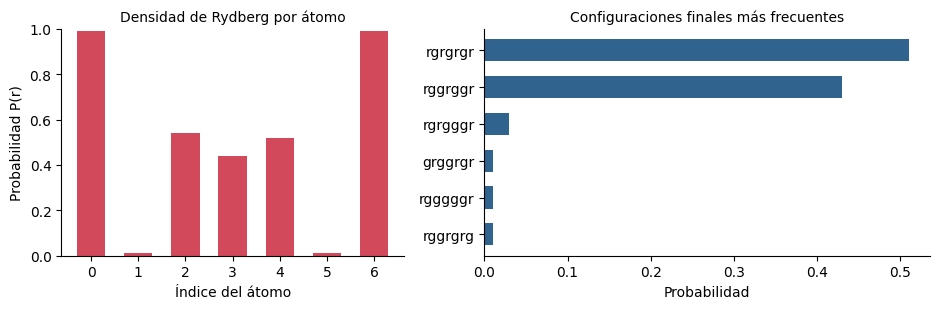

Observa cómo los átomos pares (0, 2, 4, 6) presentan alta probabilidad de estar en 'r',
mientras que los impares (1, 3, 5) permanecen en 'g', reflejando el orden antiferromagnético Z₂.


In [7]:
density = rydberg_density(local_counts, n_atoms)
top_states = list(local_counts.items())[:6]

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(9.5, 3.2), gridspec_kw={"width_ratios": [1, 1.3]})

# 1. Densidad de Rydberg por átomo
ax_left.bar(range(n_atoms), density, color="#d1495b", width=0.6)
ax_left.set_ylim(0, 1)
ax_left.set_xlabel("Índice del átomo")
ax_left.set_ylabel("Probabilidad P(r)")
ax_left.set_title("Densidad de Rydberg por átomo", fontsize=10)
ax_left.set_xticks(range(n_atoms))

# 2. Estados finales más frecuentes
states = [s for s, _ in top_states]
probs = [c / sum(local_counts.values()) for _, c in top_states]
ax_right.barh(states, probs, color="#30638e", height=0.6)
ax_right.invert_yaxis()
ax_right.set_xlabel("Probabilidad")
ax_right.set_title("Configuraciones finales más frecuentes", fontsize=10)

for ax in (ax_left, ax_right):
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()

print(f"Observa cómo los átomos pares (0, 2, 4, 6) presentan alta probabilidad de estar en 'r',")
print(f"mientras que los impares (1, 3, 5) permanecen en 'g', reflejando el orden antiferromagnético Z₂.")


## Hardware real: QuEra Aquila en Amazon Braket

[QuEra Aquila](https://www.quera.com/aquila) es el primer computador cuántico comercial de átomos neutros disponible en la nube a través de **Amazon Braket** (en la región `us-east-1`, Virginia).

### Consideraciones clave para hardware real:
1. **Credenciales y entorno AWS**:
   - Requiere una cuenta AWS con permisos para Amazon Braket y un bucket de S3 configurado.
   - Puedes configurar tus credenciales mediante `aws configure` en tu terminal o asignando las variables de entorno `AWS_ACCESS_KEY_ID`, `AWS_SECRET_ACCESS_KEY` y `AWS_DEFAULT_REGION="us-east-1"`.
2. **Coste**:
   - Braket factura \$0.30 USD por tarea (*quantum task*) + $0.01 USD por disparo (*shot*).
   - Por ejemplo, un trabajo de 100 disparos cuesta aproximadamente **$1.30 USD**.
3. **Ventanas de ejecución (*Execution Windows*)**:
   - A diferencia de los simuladores, los dispositivos físicos de átomos neutros operan en franjas horarias específicas para calibración y operación criogénica. Si envías un trabajo fuera de su ventana activa, quedará en cola hasta que la ventana se abra.
4. **Discretización (`discretize`)**:
   - El hardware físico tiene tolerancias finitas: resolución espacial mínima de pinzas ópticas (0.1 µm), tasa máxima de cambio de amplitud de láser, etc.
   - El método `program.discretize(device)` redondea y adapta automáticamente el programa ideal a las capacidades exactas de Aquila antes del envío.


## Conclusiones clave (Takeaways)

1. **Los dispositivos analógicos se programan con física, no con compuertas:** En lugar de diseñar circuitos con operaciones discretas ($H$, $CX$), programamos la **geometría espacial de los átomos** (pinzas ópticas) y la **secuencia temporal del campo láser** (amplitud Rabi $\Omega(t)$ y desintonía $\Delta(t)$). La distancia entre átomos y el radio de bloqueo $R_b$ imponen restricciones microscópicas directas.
2. **Misma plataforma cloud, diferente contrato:** Amazon Braket permite despachar tanto circuitos de compuertas (IonQ, Rigetti, IQM) como programas analógicos AHS (QuEra Aquila), pero el hardware analógico exige validar especificaciones físicas estrictas (`discretize()`), límites de aceleración del láser y ventanas horarias de disponibilidad física.
3. **Límite de la simulación clásica:** La simulación exacta de la ecuación de Schrödinger escala exponencialmente con $2^N$. Con 9 átomos ya resulta costoso simular el sistema continuo en un portátil clásico; simular 30 o 50 átomos es prohibitivo. QuEra Aquila manipula **256 átomos simultáneos**, operando de forma natural en el régimen donde los computadores cuánticos analógicos exploran fases cuánticas de la materia y resuelven problemas de optimización combinatoria como el Conjunto Independiente Máximo (*Maximum Independent Set* - MIS).
